# ML-09 — Validation and Research Claim Audit

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piasa19/flyrank-ml-internship-starter/blob/main/work/notebooks/w06_validation_audit.ipynb)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Two paper findings + my methodology questions

*Pick two findings from the FlyRank research paper. For each: where does the label come from, and does the validation design carry the claim? Constructive tone.*

### Finding 1: <paraphrase the paper's finding in one sentence>
**Methodology question (label):** Where does the label for this finding come from? <e.g. is it a measured outcome or a proxy, and how long after the action was it recorded?>
**Methodology question (validation):** Does the validation design support the claim? <e.g. are items from the same site or client split across train and test?>
**Why I ask:** The paper was written for a broad audience and discloses its standards. I am practicing the next level of rigor, not grading it. A reader could check this question with <one concrete check>.

### Finding 2: <paraphrase the second finding>
**Methodology question (label):** <...>
**Methodology question (validation):** <...>
**Why I ask:** <...>

## 2. My model under an honest split (before/after)

*Re-run your Week-5 model under a grouped or time-aware split. Show both numbers.*

In [4]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

DATA_PATH = "/content/content_refresh_anonymized.csv"
GROUP_COL = "client_id"
K, SEED = 50, 42

assert os.path.exists(DATA_PATH), f"Upload the CSV first (Colab Files sidebar). Looked for: {DATA_PATH}"
df = pd.read_csv(DATA_PATH)

# --- Week-5 proxy label: REPLACE with the exact rule from your Week-5 notebook ---
df["needs_refresh"] = (df["clicks_last_30d"] < df["clicks_prev_30d"]).astype(int)   # EXAMPLE ONLY
TARGET = "needs_refresh"
LABEL_SOURCES = ["clicks_last_30d", "clicks_prev_30d"]   # every column the label rule uses
DERIVED_FROM_LABEL = ["trend_pct", "trend_direction"]    # columns computed from those same sources
# ---------------------------------------------------------------------------------

df = df.dropna(subset=[TARGET, GROUP_COL]).reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)
groups, y = df[GROUP_COL], df[TARGET]

# Week-5 style feature set: all numeric columns except target, ids, group
ID_LIKE = [c for c in df.columns if re.search(r"(^|_)id$", c, re.I)]
FEATURES_W5 = [c for c in df.select_dtypes("number").columns if c not in {TARGET, *ID_LIKE}]
# Cleaned feature set: also remove label sources and anything derived from them
REMOVED = [c for c in FEATURES_W5 if c in set(LABEL_SOURCES) | set(DERIVED_FROM_LABEL)]
FEATURES = [c for c in FEATURES_W5 if c not in REMOVED]

print(f"rows={len(df)} | groups={groups.nunique()} | positive rate={y.mean():.3f}")
print(f"Week-5 style features: {len(FEATURES_W5)} | cleaned: {len(FEATURES)} | removed: {REMOVED}")

def make_model():
    # swap in your exact Week-5 model here
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))

def precision_at_k(y_true, scores, k):
    k = min(k, len(scores))
    return np.asarray(y_true)[np.argsort(-np.asarray(scores))[:k]].mean()

def fold_metrics(y_true, scores):
    auc = roc_auc_score(y_true, scores) if len(np.unique(y_true)) > 1 else np.nan
    return {"auc": auc, "p_at_k": precision_at_k(y_true, scores, K)}

def run_cv(cv, feats, groups_arg=None):
    X = df[feats]
    oof, rows = np.full(len(y), np.nan), []
    for tr, te in cv.split(X, y, groups_arg):
        m = make_model().fit(X.iloc[tr], y.iloc[tr])
        sc = m.predict_proba(X.iloc[te])[:, 1]
        oof[te] = sc
        rows.append(fold_metrics(y.iloc[te], sc))
    return oof, pd.DataFrame(rows)

rows=30000 | groups=32 | positive rate=0.227
Week-5 style features: 30 | cleaned: 27 | removed: ['clicks_last_30d', 'clicks_prev_30d', 'trend_pct']


,ROC AUC (measured),Precision@50 (measured)
"A. Random split, Week-5 features (before)",0.997,1.000
"B. Grouped split, Week-5 features",0.997,1.000
"C. Grouped split, cleaned features (after)",0.903,0.928


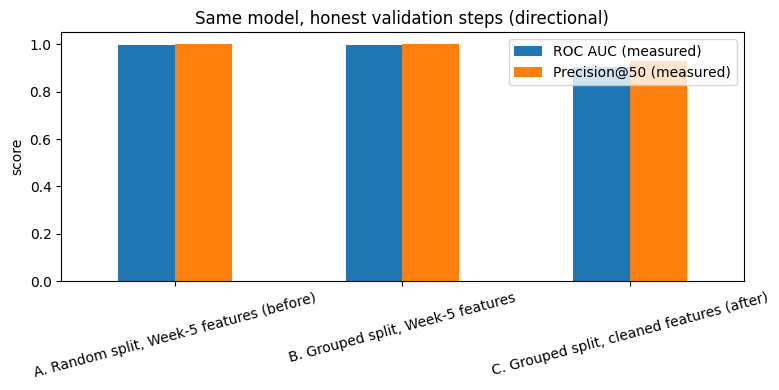

Per-fold spread (C):


,auc,p_at_k
mean,0.903,0.928
std,0.050,0.030
min,0.832,0.880
max,0.955,0.960


In [5]:
n_rand = max(2, min(5, int(y.value_counts().min())))
n_grp  = max(2, min(5, groups.nunique()))

_, r1 = run_cv(StratifiedKFold(n_rand, shuffle=True, random_state=SEED), FEATURES_W5)   # before
_, r2 = run_cv(GroupKFold(n_grp), FEATURES_W5, groups)                                   # split fixed
oof_grp, r3 = run_cv(GroupKFold(n_grp), FEATURES, groups)                                # split + features fixed

summary = pd.DataFrame({
    "A. Random split, Week-5 features (before)": r1.mean(),
    "B. Grouped split, Week-5 features": r2.mean(),
    "C. Grouped split, cleaned features (after)": r3.mean(),
}).T.round(3)
summary.columns = ["ROC AUC (measured)", f"Precision@{K} (measured)"]
display(summary)

summary.plot(kind="bar", figsize=(8, 4), rot=15)
plt.title("Same model, honest validation steps (directional)")
plt.ylabel("score"); plt.tight_layout(); plt.show()

print("Per-fold spread (C):")
display(r3.describe().loc[["mean", "std", "min", "max"]].round(3))

**Observed:** Random split with Week-5 features: AUC <A>, Precision@K <A>. Grouped split, same features: AUC <B>. Grouped split with label-derived columns removed: AUC <C>, Precision@K <C>.
**Reading:** The drop from A to B is directional evidence of client overlap across train and test. The drop from B to C is directional evidence of label leakage through columns built from the same signals as the label. C is the better decision-support estimate for new clients.
**Caveat:** <number of clients, fold spread, small-sample note>

## 3. Leakage audit

*The same hunt from Week 3, on your final feature set.*

In [6]:
# 1) Single-feature strength on the Week-5 feature set: a very strong lone feature needs a source check
single = {}
for c in FEATURES_W5:
    v = df[c].fillna(df[c].median())
    if v.nunique() > 1:
        a = roc_auc_score(y, v)
        single[c] = max(a, 1 - a)
single = pd.Series(single).sort_values(ascending=False)
print("Top single-feature AUCs (Week-5 features):\n", single.head(10).round(3))
print("Flagged (> 0.85):", list(single[single > 0.85].index) or "none")

# 2) Features related to the label's own sources
print("\nRemoved as label sources or derived:", REMOVED or "none")

# 3) Client overlap under the random split
tr, te = next(StratifiedKFold(n_rand, shuffle=True, random_state=SEED).split(df, y))
print(f"\nRandom-split test rows whose client also appears in train: {groups.iloc[te].isin(set(groups.iloc[tr])).mean():.1%}")

# 4) Duplicate feature rows
print(f"Duplicate feature rows: {df[FEATURES].duplicated().mean():.1%}")

# 5) Time-window overlap: 90-day totals contain the 30-day windows
print("\nWindow-overlap columns still in the cleaned set:",
      [c for c in FEATURES if re.search(r"_90d|last_30d|prev_30d", c)] or "none")

# 6) Permutation importance on a grouped holdout (cleaned features)
tr, te = next(GroupKFold(n_grp).split(df[FEATURES], y, groups))
m = make_model().fit(df[FEATURES].iloc[tr], y.iloc[tr])
if y.iloc[te].nunique() > 1:
    pi = permutation_importance(m, df[FEATURES].iloc[te], y.iloc[te], scoring="roc_auc",
                                n_repeats=5, random_state=SEED)
    imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
else:
    imp = single[[c for c in single.index if c in FEATURES]].head(10)
print("\nTop importances (grouped holdout, cleaned):\n", imp.head(10).round(4))

Top single-feature AUCs (Week-5 features):
 clicks_prev_30d          0.906
clicks_90d               0.839
ctr                      0.807
sessions_prev_30d        0.801
impressions_prev_30d     0.799
impressions_90d          0.786
impressions_last_30d     0.772
days_with_sessions       0.763
days_with_impressions    0.754
sessions_90d             0.741
dtype: float64
Flagged (> 0.85): ['clicks_prev_30d']

Removed as label sources or derived: ['clicks_last_30d', 'clicks_prev_30d', 'trend_pct']

Random-split test rows whose client also appears in train: 100.0%
Duplicate feature rows: 0.0%

Window-overlap columns still in the cleaned set: ['impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'impressions_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'sessions_prev_30d']

Top importances (grouped holdout, cleaned):
 sessions_prev_30d       0.1137
clicks_90d              0.0700
sessions_last_3

In [7]:
view = df[FEATURES].copy()
view["client_anon"] = pd.factorize(groups)[0]   # anonymized
view["label"], view["score"] = y, oof_grp
cols = ["client_anon", "label", "score"] + imp.head(4).index.tolist()

print("False positives (high score, label 0):")
display(view[view.label == 0].sort_values("score", ascending=False).head(5)[cols].round(3))
print("False negatives (low score, label 1):")
display(view[view.label == 1].sort_values("score").head(5)[cols].round(3))

False positives (high score, label 0):


,client_anon,label,score,sessions_prev_30d,clicks_90d,sessions_last_30d,ctr
11392,3,0,0.923,14,39,3,0.30
8392,3,0,0.857,11,16,5,0.25
16642,19,0,0.850,19,25,13,0.24
10339,10,0,0.837,8,11,2,0.19
9640,11,0,0.830,15,22,11,0.49


False negatives (low score, label 1):


,client_anon,label,score,sessions_prev_30d,clicks_90d,sessions_last_30d,ctr
7844,11,1,0.027,0,2,1,0.31
13528,24,1,0.027,0,1,0,0.10
28348,3,1,0.037,0,1,2,0.67
22632,4,1,0.047,0,1,0,0.82
5802,0,1,0.047,0,1,2,0.34


**Leakage audit result:** <columns flagged and removed, what changed from B to C>
**Error pattern observed:** <e.g. false positives cluster on low-traffic pages>
**Not yet checked:** <honest limits, e.g. window overlap, no date column for a time-aware split>

## 4. Claim rewrite

*Take your own boldest sentence and rewrite it in safe language: observed, measured, directional, decision-support.*

In [8]:
b, a = r1.mean(), r3.mean()
Markdown(f"""
**Original claim:** "My model reliably identifies the content that needs a refresh."

**Rewritten claim:** "Under a grouped-by-client split with label-derived columns removed, the model showed a
measured ROC AUC of {a['auc']:.2f} and Precision@{K} of {a['p_at_k']:.2f}
(random split with the original features: {b['auc']:.2f} and {b['p_at_k']:.2f}).
This is a directional, decision-support signal on a proxy label. It has not been validated against
real refresh outcomes or on new clients beyond this sample."
""")


**Original claim:** "My model reliably identifies the content that needs a refresh."

**Rewritten claim:** "Under a grouped-by-client split with label-derived columns removed, the model showed a
measured ROC AUC of 0.90 and Precision@50 of 0.93
(random split with the original features: 1.00 and 1.00).
This is a directional, decision-support signal on a proxy label. It has not been validated against
real refresh outcomes or on new clients beyond this sample."


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.